# Метрики бинарной классификации

ROC-AUC, PR-AUC, Precision, Recall, F1, Log Loss, пороги и калибровка

## 1. С чего начинается оценка

Классификатор часто выдаёт **оценку вероятности** положительного класса, например `0.78`. Чтобы получить метку `0` или `1`, мы выбираем порог: при `0.5` всё выше или равно порогу считаем положительным.

Отсюда два типа метрик:

- **Пороговые** (`precision`, `recall`, `F1`, accuracy): зависят от выбранного порога.
- **Ранжирующие** (`ROC-AUC`, `PR-AUC`): оценивают порядок объектов по score, не фиксируя один порог.

Есть и **вероятностные** метрики (`log loss`, `Brier score`): им важно, насколько правдоподобны сами вероятности.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, log_loss, brier_score_loss)
from sklearn.calibration import CalibrationDisplay

X, y = make_classification(n_samples=3500, n_features=12, n_informative=6,
                           n_redundant=2, weights=[0.9, 0.1], flip_y=0.02,
                           random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
model = LogisticRegression(max_iter=2000).fit(X_train, y_train)
score = model.predict_proba(X_test)[:, 1]
pred = (score >= 0.5).astype(int)
print('Доля положительного класса:', round(y_test.mean(), 3))

Доля положительного класса: 0.107


## 2. Confusion matrix и базовые метрики

| | Предсказали 1 | Предсказали 0 |
|---|---:|---:|
| На самом деле 1 | TP | FN |
| На самом деле 0 | FP | TN |

- TP (True Positive / Истинно-положительный): Тест говорит «да, беременна», и женщина действительно беременна. Тест сработал абсолютно верно.
- TN (True Negative / Истинно-отрицательный): Тест говорит «нет, не беременна», и женщина действительно не беременна. Тест снова прав.
- FP (False Positive / Ложно-положительный): Тест говорит «да, беременна», но на самом деле женщины не беременна. Это ложная тревога (ошибка 1-го рода).
- FN (False Negative / Ложно-отрицательный): Тест говорит «нет, не беременна», но женщина на самом деле беременна. Тест пропустил важное событие (ошибка 2-го рода).
- **Precision = TP / (TP + FP)**: среди срабатываний модели сколько настоящих? Важно, когда ложная тревога дорогая.
- **Recall (TPR) = TP / (TP + FN)**: какую долю реальных положительных случаев нашли? Важно, когда опасно пропустить случай.
- **Specificity (TNR) = TN / (TN + FP)**: какую долю отрицательных распознали правильно.
- **FPR = FP / (FP + TN) = 1 − Specificity**: доля ложных срабатываний среди отрицательных.
- **F1 = 2PR / (P + R)**: гармоническое среднее precision и recall; низкое значение одной метрики сильно снижает F1.
- **Accuracy**: доля всех верных ответов. При дисбалансе может вводить в заблуждение: предсказывая всегда 0 при 90% нулей, получим 90% accuracy.

**Нюанс:** F1 игнорирует TN и не учитывает стоимость ошибок напрямую. При разных ценах FP и FN порог лучше выбирать по бизнес-ограничениям, а не максимальному F1.

In [2]:
print(pd.DataFrame(confusion_matrix(y_test, pred),
                   index=['Факт 0', 'Факт 1'], columns=['Прогноз 0', 'Прогноз 1']))
print(pd.Series({'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred)}).round(3))

        Прогноз 0  Прогноз 1
Факт 0        930          8
Факт 1         81         31
Accuracy     0.915
Precision    0.795
Recall       0.277
F1           0.411
dtype: float64


### Как читать матрицу ошибок на графике

**Строки — реальные классы, столбцы — предсказания.** Диагональ показывает правильные ответы (TN и TP). Две остальные клетки — ошибки: **FP** означает ложную тревогу, **FN** — пропущенный положительный объект. Цвет показывает количество объектов, а не долю. При дисбалансе полезно дополнительно нормировать строки.

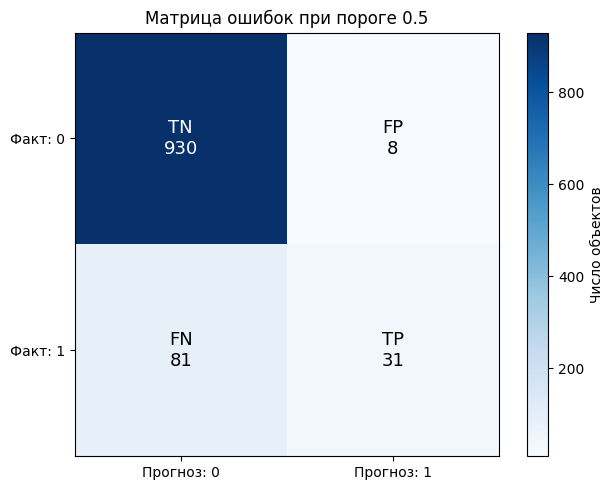

In [3]:
cm = confusion_matrix(y_test, pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(cm, cmap='Blues')
for (r, col), value in np.ndenumerate(cm):
    name = {(0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN', (1, 1): 'TP'}[(r, col)]
    ax.text(col, r, f'{name}\n{value}', ha='center', va='center', fontsize=13,
            color='white' if value > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Прогноз: 0', 'Прогноз: 1'])
ax.set_yticks([0, 1], ['Факт: 0', 'Факт: 1'])
ax.set_title('Матрица ошибок при пороге 0.5')
fig.colorbar(im, ax=ax, label='Число объектов')
plt.tight_layout()
plt.show()

## 3. ROC-кривая и ROC-AUC

ROC показывает, как при изменении порога меняются **TPR (Recall)** и **FPR**. По оси X — FPR, по Y — TPR. Хорошая кривая ближе к левому верхнему углу.

**ROC-AUC** — площадь под ROC-кривой. Удобная интерпретация: вероятность того, что случайный положительный объект получит score выше случайного отрицательного (с половинным вкладом ничьих).

- `0.5` — уровень случайного ранжирования; `1.0` — идеальное разделение.
- AUC **не говорит**, что вероятность `0.8` действительно означает 80% случаев.
- AUC **не задаёт** лучший порог и не измеряет бизнес-стоимость ошибок.

**Почему ROC-AUC может обманывать при редком классе:** даже небольшой FPR способен дать много ложных срабатываний, если отрицательных объектов очень много. Поэтому при редком положительном классе смотрите ещё и PR-кривую, а также абсолютные TP/FP.

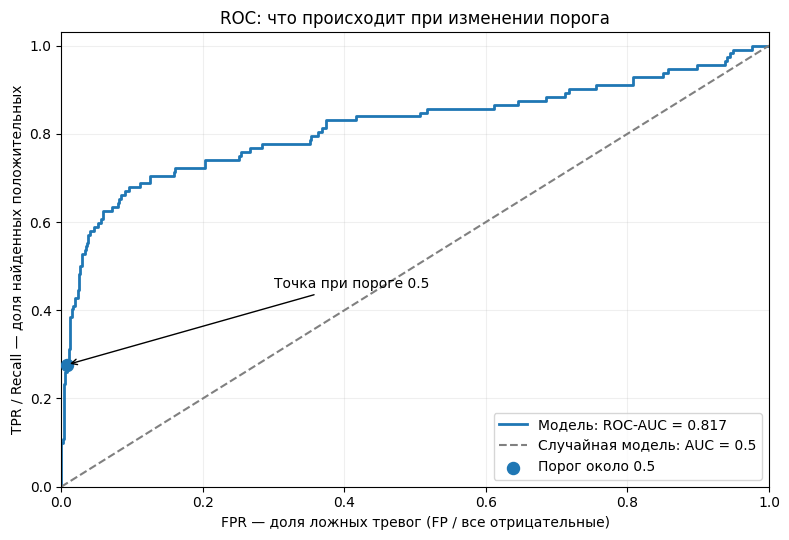

In [4]:
fpr, tpr, thresholds = roc_curve(y_test, score)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(fpr, tpr, lw=2, label=f'Модель: ROC-AUC = {roc_auc_score(y_test, score):.3f}')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Случайная модель: AUC = 0.5')
idx = np.argmin(np.abs(thresholds - 0.5))
ax.scatter(fpr[idx], tpr[idx], s=75, zorder=3, label='Порог около 0.5')
ax.annotate('Точка при пороге 0.5', (fpr[idx], tpr[idx]), xytext=(0.30, 0.45),
            arrowprops={'arrowstyle': '->'})
ax.set(xlabel='FPR — доля ложных тревог (FP / все отрицательные)',
       ylabel='TPR / Recall — доля найденных положительных',
       title='ROC: что происходит при изменении порога', xlim=(0, 1), ylim=(0, 1.03))
ax.legend(loc='lower right')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Разбор ROC-графика

- **Горизонтальная ось FPR:** какая доля настоящих нулей ошибочно получила метку 1. Чем левее, тем меньше ложных тревог.
- **Вертикальная ось TPR (Recall):** какую долю настоящих единиц нашли. Чем выше, тем меньше пропусков.
- **Пунктирная диагональ:** случайное ранжирование. **Левый верхний угол (0, 1)** — идеальный результат.
- **Отмеченная точка:** результат при пороге около 0.5. Смена порога передвигает точку вдоль линии; сама ROC-AUC от выбранного порога не зависит.

**ROC-AUC** можно понимать как вероятность, что случайному положительному объекту модель присвоит больший score, чем случайному отрицательному (с учётом половины веса совпадений). Это **не** вероятность правильного предсказания конкретного объекта. При редком классе ROC-AUC может выглядеть хорошо, хотя абсолютное число FP велико.

## 4. PR-кривая и PR-AUC / Average Precision

PR-кривая показывает зависимость **Precision от Recall** при переборе порогов. Она особенно полезна, когда положительный класс редкий и важно качество найденных срабатываний.

**Baseline precision** примерно равен доле положительного класса. Если положительных 10%, случайное ранжирование даёт около 0.10 precision в среднем.

**Важная тонкость:** `average_precision_score` (AP) и площадь под PR-кривой, вычисленная трапециями, — **не одно и то же**. В scikit-learn AP суммирует precision с весами по приросту recall; называть AP «PR-AUC» в разговоре принято, но в отчёте лучше явно указывать метод расчёта.

ROC-AUC и AP нельзя напрямую сравнивать по числам: это разные шкалы и разные базовые уровни.

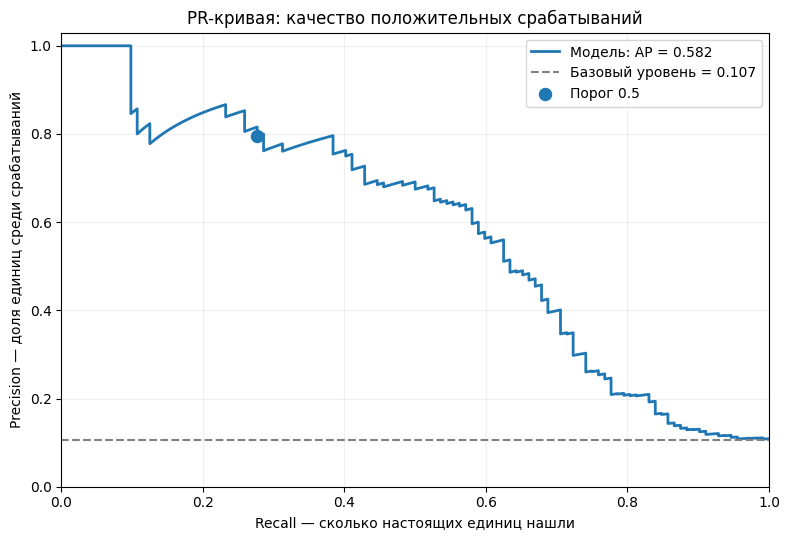

In [5]:
precision, recall, pr_thresholds = precision_recall_curve(y_test, score)
ap = average_precision_score(y_test, score)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(recall, precision, lw=2, label=f'Модель: AP = {ap:.3f}')
ax.axhline(y_test.mean(), linestyle='--', color='gray', label=f'Базовый уровень = {y_test.mean():.3f}')
ax.scatter(recall_score(y_test, pred), precision_score(y_test, pred),
           s=75, zorder=3, label='Порог 0.5')
ax.set(xlabel='Recall — сколько настоящих единиц нашли',
       ylabel='Precision — доля единиц среди срабатываний',
       title='PR-кривая: качество положительных срабатываний', xlim=(0, 1), ylim=(0, 1.03))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Разбор PR-графика

**Ось X (Recall)** показывает полноту поиска положительных объектов. **Ось Y (Precision)** — насколько можно доверять срабатываниям модели. Точка в правом верхнем углу (1, 1) идеальна: нашли всех и никого лишнего.

**Горизонтальный пунктир** — доля положительных объектов в тестовой выборке: это ориентир для случайного ранжирования. **Точка с порогом 0.5** показывает одну конкретную настройку классификатора. Если уменьшить порог, обычно Recall растёт, но Precision может упасть.

**AP (Average Precision)** — взвешенное среднее Precision по изменениям Recall, которое вычисляет `average_precision_score`. Его часто называют PR-AUC, но оно **не всегда равно** площади под PR-кривой, рассчитанной трапециями. Для редких положительных классов PR-график часто информативнее ROC.

## 5. Как выбрать порог

Порог `0.5` — технический дефолт, а не универсальный оптимум. Если пропустить мошенничество дорого, часто повышают recall, понижая порог. Если каждое срабатывание требует дорогой ручной проверки, можно ограничить число FP или требовать минимальный precision.

Выбирать порог **по тесту нельзя**: это подгонка под тестовые ответы. Ниже демонстрация влияния порога на одном тестовом наборе **только для обучения**. В реальной работе подбирайте порог на validation / out-of-fold предсказаниях, затем один раз оценивайте на test.

In [6]:
rows = []
for t in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    p = (score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    rows.append({'Порог': t, 'Precision': precision_score(y_test, p, zero_division=0),
                 'Recall': recall_score(y_test, p, zero_division=0),
                 'F1': f1_score(y_test, p, zero_division=0), 'FP': fp, 'FN': fn})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 Порог  Precision  Recall    F1  FP  FN
   0.1      0.251   0.768 0.378 257  26
   0.2      0.412   0.688 0.515 110  35
   0.3      0.600   0.589 0.595  44  46
   0.5      0.795   0.277 0.411   8  81
   0.7      0.917   0.098 0.177   1 101
   0.9      1.000   0.009 0.018   0 111


### Как порог влияет на метрики

Ниже по **оси X — порог вероятности**, по **оси Y — значение метрики от 0 до 1**. Низкий порог обычно помогает находить больше положительных объектов (Recall), но увеличивает число ложных срабатываний. Высокий порог делает модель осторожнее. **F1** помогает искать компромисс, но не учитывает денежную стоимость ошибок.

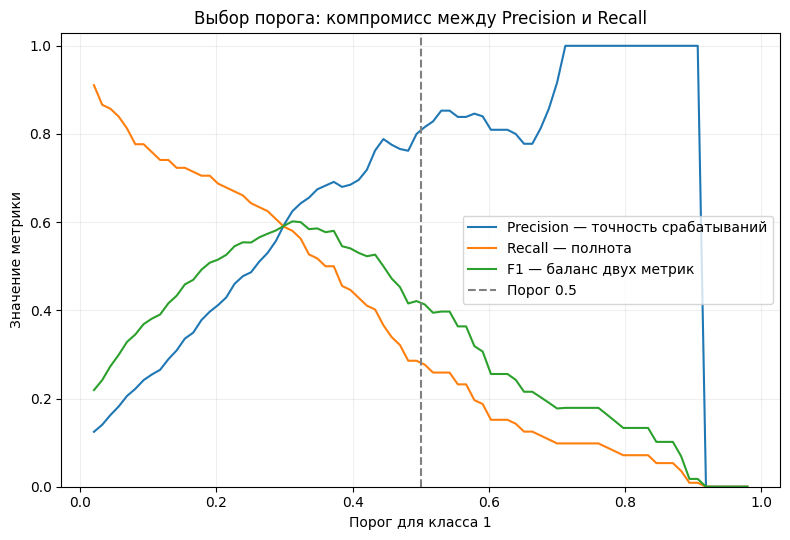

In [7]:
grid = np.linspace(0.02, 0.98, 80)
p_vals, r_vals, f_vals = [], [], []
for threshold in grid:
    predicted = (score >= threshold).astype(int)
    p_vals.append(precision_score(y_test, predicted, zero_division=0))
    r_vals.append(recall_score(y_test, predicted, zero_division=0))
    f_vals.append(f1_score(y_test, predicted, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(grid, p_vals, label='Precision — точность срабатываний')
ax.plot(grid, r_vals, label='Recall — полнота')
ax.plot(grid, f_vals, label='F1 — баланс двух метрик')
ax.axvline(0.5, linestyle='--', color='gray', label='Порог 0.5')
ax.set(xlabel='Порог для класса 1', ylabel='Значение метрики',
       title='Выбор порога: компромисс между Precision и Recall', ylim=(0, 1.03))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Практический вывод:** выбирать порог по тестовой выборке нельзя — так возникает подгонка под тест. Подбирайте порог на отдельной валидации или через out-of-fold предсказания, а финальную оценку делайте на нетронутом тесте.

## 6. Log Loss и Brier Score: качество вероятностей (опционально)

Две модели могут одинаково ранжировать объекты (и иметь одинаковый ROC-AUC), но одна выдаёт адекватные вероятности, а другая слишком уверена.

**Log Loss** для бинарной классификации:

$$-rac{1}{n}\sum_i [y_i\log(p_i)+(1-y_i)\log(1-p_i)]$$

Он сильно штрафует уверенные ошибки. **Brier Score** — средний квадрат разности между вероятностью и фактической меткой: $rac{1}{n}\sum_i(p_i-y_i)^2$.

У обеих метрик **меньше — лучше**. Их значения зависят от распространённости класса и сложности данных. Для интерпретации сравнивайте с разумным baseline.

**Калибровка** означает: среди объектов, которым модель назначила вероятность около 0.7, положительных действительно около 70%. Калибровка важна для оценки рисков, но не гарантирует высокий AUC.

Log Loss: 0.253
Brier Score: 0.0665


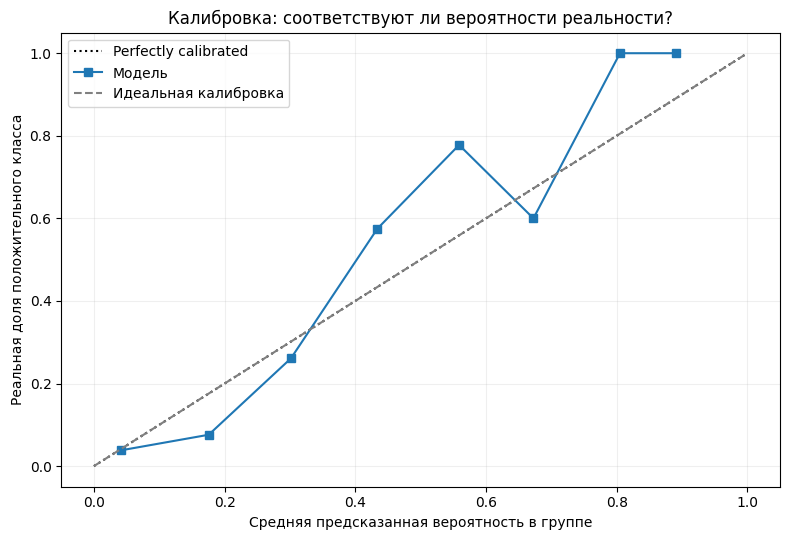

In [8]:
print('Log Loss:', round(log_loss(y_test, score), 4))
print('Brier Score:', round(brier_score_loss(y_test, score), 4))
fig, ax = plt.subplots(figsize=(8, 5.5))
CalibrationDisplay.from_predictions(y_test, score, n_bins=8, ax=ax, name='Модель')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Идеальная калибровка')
ax.set(xlabel='Средняя предсказанная вероятность в группе',
       ylabel='Реальная доля положительного класса',
       title='Калибровка: соответствуют ли вероятности реальности?')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Разбор графика калибровки

Каждая точка — группа объектов с близкими предсказанными вероятностями. **По X** — средняя вероятность, которую выдала модель. **По Y** — реальная доля единиц в этой группе. Например, если для группы модель говорит «примерно 0.7», в хорошо откалиброванной модели около 70% объектов должны быть положительными.

**Диагональ** означает идеальное совпадение. **Точки ниже диагонали** — модель переоценивает вероятность события, **выше** — недооценивает. На краях графика данных может быть мало, поэтому отдельные точки там ненадёжны.

**Log Loss** сильно штрафует уверенные неправильные прогнозы. **Brier Score** — средняя квадратичная ошибка вероятностей. Для обеих метрик **меньше — лучше**. Хорошая калибровка не гарантирует хорошее ранжирование, и наоборот.

## 7. Дисбаланс классов и корректная проверка

Если положительных 1%, модель «всегда 0» даёт 99% accuracy и 0 recall. Поэтому при дисбалансе оценивайте **AP, precision/recall при нужном пороге, число FP и FN**, а также ROC-AUC для общей способности ранжировать.

**Stratified split / StratifiedKFold** сохраняет примерные доли классов в частях данных. Для временных данных нужен временной сплит; для повторяющихся пользователей — групповой, иначе возможна утечка. Препроцессинг обучают только на train, обычно внутри `Pipeline`.

Проверяйте, не меняется ли доля положительного класса в продакшене: precision и AP могут существенно измениться даже при похожих ROC-кривых.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_cv = cross_val_score(LogisticRegression(max_iter=2000), X_train, y_train,
                         cv=cv, scoring='roc_auc')
ap_cv = cross_val_score(LogisticRegression(max_iter=2000), X_train, y_train,
                        cv=cv, scoring='average_precision')
print(f'ROC-AUC CV: {auc_cv.mean():.3f} ± {auc_cv.std():.3f}')
print(f'AP CV: {ap_cv.mean():.3f} ± {ap_cv.std():.3f}')

ROC-AUC CV: 0.821 ± 0.031
AP CV: 0.524 ± 0.085


**Macro / micro / weighted** (для нескольких классов): macro усредняет метрику по классам одинаково; weighted учитывает размер каждого класса; micro сначала суммирует TP/FP/FN. При редких классах macro помогает увидеть провалы, которые скрывает weighted.

**ROC-AUC для multiclass** требует выбора стратегии (`ovr` или `ovo`) и усреднения; не переносите бинарную интерпретацию автоматически на все варианты.

**Precision@K / Recall@K** полезны, если команда может проверить только K объектов в день. Тогда порог по вероятности иногда менее удобен, чем top-K.

**Стоимость ошибок:** задайте цену FP и FN и выбирайте решение по ожидаемым потерям. Метрика качества модели и метрика полезности решения — не всегда одно и то же.

**Доверительные интервалы:** разница AUC 0.81 и 0.82 может оказаться шумом. Для серьёзного сравнения полезны bootstrap-интервалы на независимом тесте и проверка стабильности на разных периодах.

**Data leakage:** даже очень высокий AUC бесполезен, если в признаки попала информация из будущего или из целевой переменной.

## 9. Краткая шпаргалка

| Ситуация | Что смотреть в первую очередь |
|---|---|
| Нужен общий рейтинг объектов | ROC-AUC |
| Редкий положительный класс | Average Precision + PR-кривая |
| Дорогие ложные тревоги | Precision, FP, Precision@K |
| Дорогие пропуски | Recall, FN |
| Нужен баланс precision/recall | F1 или F-beta с обоснованным beta |
| Важны корректные вероятности | Log Loss, Brier, калибровка |
| Нужно принять решение в продакшене | Метрика + порог + стоимость ошибок + мониторинг |

**Вопросы для самопроверки:** Почему AUC не зависит от конкретного порога? Почему AP зависит от распространённости класса? Почему нельзя подбирать порог на тесте? Может ли AUC быть хорошим при плохой калибровке? Что выбрать, если аналитики успевают проверить 100 заявок в день?